Programming for Data Analytics POE 

The medical scheme wants to be able to analyse customer reviews to identify recurring themes in customer feedback and understand the sentiment expressed in those reviews. Topic modelling will be used to explore what customers discuss, while sentiment analysis will examine whether their experiences are positive, negative or neutral.

Because the scheme’s own reviews are not available, Yelp reviews of US healthcare providers are used as a proxy

## Business Objectives 

1. Identify what customers are saying in healthcare reviews that mention insurance and billing, used as a proxy for what medical scheme members would say (concerns and recurring patterns): Latent Dirichlet Allocation (LDA) will be used to discover common topics and patterns within customer reviews.
2. Understand how customers feel in healthcare reviews that mention insurance and billing, used as a proxy for what medical scheme members would say (customer sentiments): VADER and TextBlob will be used to classify reviews as positive, negative, or neutral and compare the results.

The analysis findings will be used to identify patterns in customer feedback (star ratings and text reviews) and provide practical recommendations to improve the customer experience. 

## Dataset Selection and Suitability 

Yelp reviews of health and medical providers are customers describing their experience of a healthcare service, which is the same kind of feedback a medical scheme receives. Each review has a 1-5 star rating, the text is detailed, and the dataset is released for educational use.
Filtering for words like *insurance*, *billing* and *claim* keeps the complaints close to what a scheme cares about.

**What the analysis needs from the data**
- LDA needs many reviews, with enough words in each review and a variety of topics. The Health & Medical businesses have 188,041 reported reviews, which is more than enough, and a minimum review length is applied during cleaning.
- Sentiment analysis needs free text and a way to check the results. The 1-5 star rating of each review is used as that check.

**Data quality and limitations considered**
- The reviews are from US healthcare providers, not South African medical schemes, so the findings show shared service concerns (billing, claims, communication) rather than one scheme's exact problems.
- Reviewers choose to write reviews, so opinions tend to be extreme and may not represent all customers.
- Star ratings are only a proxy for sentiment, because a review can have a low rating but a neutral tone.
- Star ratings are likely to be unevenly spread across negative, neutral and positive, which affects how the sentiment results are judged.
- Duplicate, empty and very short reviews can distort topics and sentiment, so they are checked for and removed during cleaning.

Other datasets considered 
HelloPeter reviews on South African medical aids were considered for easier relatability to the South African context but because the website's terms of use prohibit web scraping they were not used  

## Algorithm Selection

**Business objective 1 (What customers say?)** 

For topic modelling, Latent Dirichlet Allocation (LDA) will be used. The reviews have no topic labels, so an unsupervised method is needed. LDA treats each review as a mix of topics and each topic as a set of words, which gives the client interpretable themes. Its limitations are that the number of topics must be chosen, so topic counts and alpha values will be compared using coherence, and that topics need human interpretation.
- Algorithms not used
NMF could also find topics, but it gives no probabilities for how much of each review belongs to each topic. Clustering such as k-means forces each review into a single group, which suits reviews that mention several issues poorly.

**Business objective 2 (How customers feel?)**

For sentiment analysis, VADER and TextBlob will be used. Both are lexicon-based, so they need no labelled training data and can be applied immediately. VADER is designed for informal text and handles capitalisation, punctuation and negation, while TextBlob offers a second view for comparison.
- Algorithms not used
Supervised classifiers or transformer models could be more accurate, but they need labelled data and more time and computing power, which is not justified for this client question. Results are checked against star-based labels.


# Analysis Planning 

Below is the plan which will be followed when conducting the analysis 


Analysis plan

- Data collection: Obtain and inspect the Yelp Health & Medical dataset, including its size, columns and data types.
- Exploratory Data Analysis (EDA): Check missing values, duplicates and empty reviews. Analyse review lengths, word frequencies and star-rating distributions using charts and word clouds.
- Data preprocessing: Clean review text, remove stop words, apply lemmatisation and prepare text for analysis.
- Feature selection: Use CountVectorizer for LDA and experiment with min_df, max_df and max_features to refine the vocabulary.
- Topic modelling: Apply LDA, experiment with the number of topics and alpha settings, and evaluate topic coherence.
- Sentiment analysis: Apply VADER and TextBlob to classify reviews as positive, negative or neutral. Experiment with sentiment cut-offs.
- Model evaluation: Compare sentiment predictions with Yelp star-based labels using confusion matrices, F1-score and negative recall. Manually inspect selected reviews.
- Reporting: Present EDA findings, model results, topic interpretations, limitations and recommendations.

# Import Libraries 
All the libraries needed to conduct the analysis are loaded into the notebook

In [1]:
# Install the libraries that may not be installed yet (run once, then restart the kernel if asked)
%pip install -q vaderSentiment textblob wordcloud

Note: you may need to restart the kernel to use updated packages.


In [2]:
## Importing libraries for analysis 

import os, re, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, recall_score)

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
from wordcloud import WordCloud

nltk.download('stopwords', quiet=True)   # English stopword list
nltk.download('wordnet', quiet=True)     # dictionary used by the lemmatiser
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [3]:
# Define the paths to the Yelp dataset files

DATA_DIR = "."   # folder holding the Yelp files (the same folder as this notebook)

BUSINESS_FILE = os.path.join(DATA_DIR, "yelp_academic_dataset_business.json")

REVIEW_FILE = os.path.join(DATA_DIR, "yelp_academic_dataset_review.json")

# Set reproducibility and processing settings

RANDOM_SEED = 42
SAMPLE_SIZE = 30000
MIN_WORDS = 10
CHUNK_SIZE = 50000

print("Dataset paths and project settings configured.")

Dataset paths and project settings configured.


In [4]:
# Check whether the required dataset files can be found

print("Business file found:", os.path.exists(BUSINESS_FILE))
print("Review file found:", os.path.exists(REVIEW_FILE))

# Display file sizes if the files exist

if os.path.exists(BUSINESS_FILE):
    business_size = os.path.getsize(BUSINESS_FILE) / (1024 ** 2)
    print(f"Business file size: {business_size:.2f} MB")

if os.path.exists(REVIEW_FILE):
    review_size = os.path.getsize(REVIEW_FILE) / (1024 ** 3)
    print(f"Review file size: {review_size:.2f} GB")

Business file found: True
Review file found: True
Business file size: 113.36 MB
Review file size: 4.98 GB


In [5]:
# Load the business JSON file

business_df = pd.read_json(BUSINESS_FILE, lines=True)

print("Business dataset loaded successfully.")

Business dataset loaded successfully.


# Exploratory Data Analytics

In [6]:
# Display the number of rows and columns

print("Rows:", business_df.shape[0])
print("Columns:", business_df.shape[1])

Rows: 150346
Columns: 14


There are 150 346 rows and 14 columns found in the dataset 

In [7]:
# Display all available columns

print(business_df.columns.tolist())

['business_id', 'name', 'address', 'city', 'state', 'postal_code', 'latitude', 'longitude', 'stars', 'review_count', 'is_open', 'attributes', 'categories', 'hours']


In [8]:
# Display first 20 business records
business_df.head(20)

,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', ..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,101 Walnut St,Green Lane,PA,18054,40.338183,-75.471659,4.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Wheelc...","Brewpubs, Breweries, Food","{'Wednesday': '14:0-22:0', 'Thursday': '16:0-2..."
5,CF33F8-E6oudUQ46HnavjQ,Sonic Drive-In,615 S Main St,Ashland City,TN,37015,36.269593,-87.058943,2.0,6,1,"{'BusinessParking': 'None', 'BusinessAcceptsCr...","Burgers, Fast Food, Sandwiches, Food, Ice Crea...","{'Monday': '0:0-0:0', 'Tuesday': '6:0-22:0', '..."
6,n_0UpQx1hsNbnPUSlodU8w,Famous Footwear,"8522 Eager Road, Dierbergs Brentwood Point",Brentwood,MO,63144,38.627695,-90.340465,2.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Restau...","Sporting Goods, Fashion, Shoe Stores, Shopping...","{'Monday': '0:0-0:0', 'Tuesday': '10:0-18:0', ..."
7,qkRM_2X51Yqxk3btlwAQIg,Temple Beth-El,400 Pasadena Ave S,St. Petersburg,FL,33707,27.766590,-82.732983,3.5,5,1,None,"Synagogues, Religious Organizations","{'Monday': '9:0-17:0', 'Tuesday': '9:0-17:0', ..."
8,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,8025 Mackenzie Rd,Affton,MO,63123,38.565165,-90.321087,3.0,19,0,"{'Caters': 'True', 'Alcohol': 'u'full_bar'', '...","Pubs, Restaurants, Italian, Bars, American (Tr...",None
9,bBDDEgkFA1Otx9Lfe7BZUQ,Sonic Drive-In,2312 Dickerson Pike,Nashville,TN,37207,36.208102,-86.768170,1.5,10,1,"{'RestaurantsAttire': ''casual'', 'Restaurants...","Ice Cream & Frozen Yogurt, Fast Food, Burgers,...","{'Monday': '0:0-0:0', 'Tuesday': '6:0-21:0', '..."


The first 20 business records are displayed to better see what some of the business included in the analysis will be and what their details are.

In [9]:
# Check the data type of each column

business_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150346 entries, 0 to 150345
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   business_id   150346 non-null  str    
 1   name          150346 non-null  str    
 2   address       150346 non-null  str    
 3   city          150346 non-null  str    
 4   state         150346 non-null  str    
 5   postal_code   150346 non-null  str    
 6   latitude      150346 non-null  float64
 7   longitude     150346 non-null  float64
 8   stars         150346 non-null  float64
 9   review_count  150346 non-null  int64  
 10  is_open       150346 non-null  int64  
 11  attributes    136602 non-null  object 
 12  categories    150243 non-null  str    
 13  hours         127123 non-null  object 
dtypes: float64(3), int64(2), object(2), str(7)
memory usage: 35.4+ MB


In [10]:
# Count missing values in each column

business_df.isnull().sum()

business_id         0
name                0
address             0
city                0
state               0
postal_code         0
latitude            0
longitude           0
stars               0
review_count        0
is_open             0
attributes      13744
categories        103
hours           23223
dtype: int64

The fields "attributes", "categories" and "hours" had 13744, 103 and 23223 missing values respectively. This does not affect the analysis because the businesses are selected using the business_id and categories fields.

In [11]:
# Select businesses belonging to the Health & Medical category

health_businesses = business_df[
    business_df["categories"].fillna("").str.contains(
        "Health & Medical", case=False, regex=False
    )
].copy()

print("Health & Medical businesses:", len(health_businesses))

Health & Medical businesses: 11890


In [12]:
# Display a sample of Health & Medical businesses

display(
    health_businesses[["business_id", "name", "categories", "stars", "review_count"]].head(10)
)

,business_id,name,categories,stars,review_count
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","Doctors, Traditional Chinese Medicine, Naturop...",5.0,7
13,jaxMSoInw8Poo3XeMJt8lQ,Adams Dental,"General Dentistry, Dentists, Health & Medical,...",5.0,10
43,Kq51_lGAgAigqmENITTr-A,Bala Better Health,"Health & Medical, Beauty & Spas, Laser Hair Re...",4.0,13
57,DQ7PyYlp2bX96WZa7TcaWQ,LensCrafters,"Ophthalmologists, Eyewear & Opticians, Health ...",2.5,8
74,9Rww8yE6Dm4dSMEq09nwXg,Holly Nails & Spa,"Health & Medical, Personal Care Services, Beau...",4.5,16
100,8KMIT0NXu30Jz5Ojo5uxaw,Cornerstone Physical Therapy Associates,"Fitness & Instruction, Physical Therapy, Healt...",5.0,6
111,H0NEOp4e3Zu598u6kO3y0g,America's Best Contacts & Eyeglasses,"Eyewear & Opticians, Health & Medical, Shoppin...",3.5,17
128,P8brGDYVWjeW9GrKixH0yQ,Laser Spine Institute,"Medical Centers, Doctors, Diagnostic Services,...",3.0,36
137,E_kLUlU60fzoZYAOxbH_3w,Pain Institute of Southern Arizona,"Pain Management, Doctors, Health & Medical, Os...",2.5,43
146,M_THnNDHs29aylcK-JqS1A,Professional Healthcare of Pinellas,"Doctors, Internal Medicine, Health & Medical",1.5,6


In [13]:
# Examine the ratings and review counts of selected businesses

print("Number of businesses:", len(health_businesses))
print("Average business rating:", round(health_businesses["stars"].mean(), 2))
print("Total reported reviews:", health_businesses["review_count"].sum())

Number of businesses: 11890
Average business rating: 3.63
Total reported reviews: 188041


Out of the 150,346 businesses, 11,890 are in the Health & Medical category. They have an average rating of 3.63 stars and 188,041 reported reviews. Only the IDs of these businesses are used to select the reviews for the analysis.

# Loading the Review Data
The review file is several GB, so it is read in chunks. Only reviews of Health & Medical businesses that mention insurance, billing or claim-related words are kept, then a random sample is saved so this slow step only runs once.

In [14]:
# Settings for filtering the reviews and saving the sample
SAMPLE_FILE = 'reviews_sample.csv'      # saved sample so the huge file is only read once

# Words that point to scheme-style concerns (insurance, billing, claims, coverage, authorisation)
PATTERN = (r'\b(?:insurance|insurer|claims?|billing|bills?|copay|co-pay|deductible|coverage|covered|'
           r'authori[sz]ation|referral|in-network|out-of-network|out of network)\b')

# IDs of the Health & Medical businesses selected earlier
health_ids = set(health_businesses['business_id'])
print('Health & Medical businesses:', len(health_ids))

Health & Medical businesses: 11890


In [15]:
# Read the review file in chunks, keep matching reviews, take a sample and save it
if os.path.exists(SAMPLE_FILE):
    df = pd.read_csv(SAMPLE_FILE)
    print('Loaded saved sample:', df.shape)
else:
    kept = []
    for chunk in pd.read_json(REVIEW_FILE, lines=True, chunksize=CHUNK_SIZE, dtype=False, convert_dates=False):
        chunk = chunk[chunk['business_id'].isin(health_ids)]                                    # health businesses only
        chunk = chunk[chunk['text'].str.contains(PATTERN, case=False, regex=True, na=False)]    # keyword match
        kept.append(chunk[['review_id', 'business_id', 'stars', 'date', 'text']])               # user IDs dropped for privacy
    df = pd.concat(kept, ignore_index=True)
    print('Matching reviews found:', len(df))
    if len(df) > SAMPLE_SIZE:
        df = df.sample(SAMPLE_SIZE, random_state=RANDOM_SEED).reset_index(drop=True)
    df.to_csv(SAMPLE_FILE, index=False)
    print('Sample saved:', df.shape)

Loaded saved sample: (24685, 5)


# Exploratory Data Analytics of the Reviews

In [16]:
# Size, data types and missing values of the review sample
print(df.shape)
df.info()
print('\nMissing values per column:')
print(df.isna().sum())

(24685, 5)
<class 'pandas.DataFrame'>
RangeIndex: 24685 entries, 0 to 24684
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   review_id    24685 non-null  str    
 1   business_id  24685 non-null  str    
 2   stars        24685 non-null  float64
 3   date         24685 non-null  str    
 4   text         24685 non-null  str    
dtypes: float64(1), str(4)
memory usage: 28.4 MB

Missing values per column:
review_id      0
business_id    0
stars          0
date           0
text           0
dtype: int64


In [17]:
# Duplicate and short-review checks.
# Duplicates are checked on the review text itself (and the review ID), because a whole-row check
# could miss identical text that has a different ID.
cleaning_log = {'rows_loaded': len(df)}
df['n_words'] = df['text'].fillna('').str.split().str.len()      # review length in words

print('Duplicate review IDs  :', df.duplicated(subset=['review_id']).sum())
print('Duplicate review text :', df.duplicated(subset=['text']).sum())
print(f'Empty or very short reviews (under {MIN_WORDS} words):', (df['n_words'] < MIN_WORDS).sum())

Duplicate review IDs  : 0
Duplicate review text : 86
Empty or very short reviews (under 10 words): 3


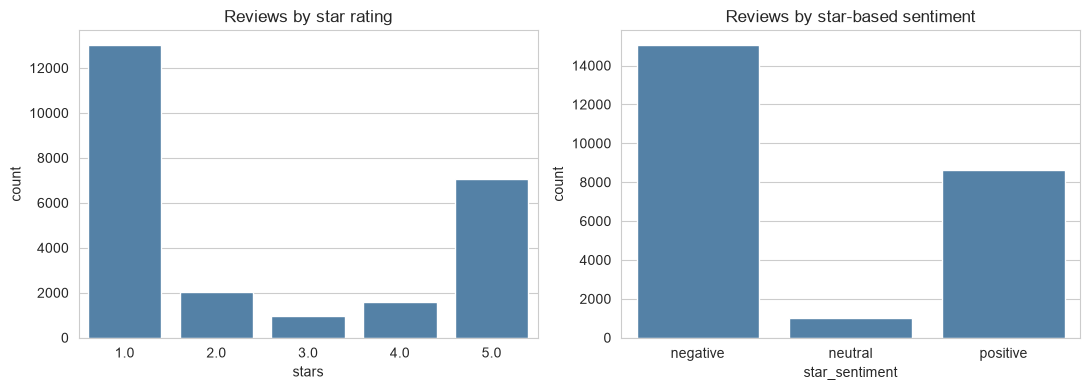

star_sentiment
negative    61.0
positive    35.0
neutral      4.0
Name: proportion, dtype: float64


In [18]:
# Star-based sentiment labels, used only to CHECK the sentiment tools later:
# 1-2 stars = negative, 3 = neutral, 4-5 = positive
def star_label(stars):
    if stars <= 2: return 'negative'
    if stars == 3: return 'neutral'
    return 'positive'

df['star_sentiment'] = df['stars'].apply(star_label)

# Star rating distribution (shows class balance, which matters for evaluation)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='stars', data=df, ax=ax[0], color='steelblue')
ax[0].set_title('Reviews by star rating')
sns.countplot(x='star_sentiment', data=df, order=['negative', 'neutral', 'positive'], ax=ax[1], color='steelblue')
ax[1].set_title('Reviews by star-based sentiment')
plt.tight_layout(); plt.show()
print((df['star_sentiment'].value_counts(normalize=True) * 100).round(1))

**Interpretation:**
The reviews were divided into 61% negative, 35% positive and 4% neutral. Accuracy alone is misleading, and neutral results will be unreliable

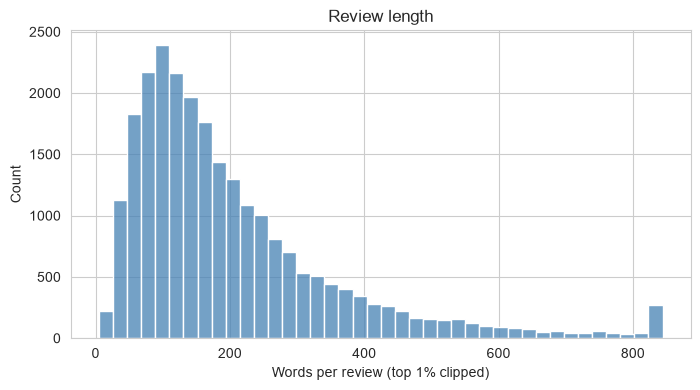

count    24685.0
mean       203.5
std        159.8
min          5.0
25%         96.0
50%        157.0
75%        258.0
max       1019.0
Name: n_words, dtype: float64


In [19]:
# Review length (shows whether reviews are long enough for topic modelling)
plt.figure(figsize=(8, 4))
sns.histplot(df['n_words'].clip(upper=df['n_words'].quantile(0.99)), bins=40, color='steelblue')
plt.xlabel('Words per review (top 1% clipped)'); plt.title('Review length'); plt.show()
print(df['n_words'].describe().round(1))

**Interpretation**

The average review in the dataset had 203 words in it, with a median of 157 words and 1019 words maximum

## Data Preprocessing

Two versions of each review are kept:
- `text` (original): used for **VADER and TextBlob**, because they use capital letters, punctuation and words like "not" to judge sentiment.
- `text_clean`: used for **LDA**, which only needs meaningful, lower-case, lemmatised words.

In [20]:
# Prepare review text for topic modelling

# Standard English stopwords and additional filler words
STOP = set(stopwords.words('english'))

CUSTOM_STOP = {
    'would', 'could', 'get', 'got', 'go', 'went', 'one',
    'also', 'even', 'really', 'said', 'told', 'like',
    'back', 'came', 'make', 'made', 'say', 'take',
    'took', 'see', 'still', 'much', 'many', 'always',
    'never', 'every', 'lot', 'just', 'know', 'want', 'wanted'
}

STOP_ALL = STOP | CUSTOM_STOP
lemmatizer = WordNetLemmatizer()

# Remove missing, empty and duplicate reviews
df = df.dropna(subset=['text', 'stars'])
df['text'] = df['text'].str.strip()
df = df[df['text'] != '']

df = df.drop_duplicates(subset=['review_id'])
df = df.drop_duplicates(subset=['text'])

# Apply the minimum original review length
df['n_words'] = df['text'].str.split().str.len()
df = df[df['n_words'] >= MIN_WORDS].copy()

# Clean text for LDA
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r"[^a-z\s]", ' ', text)

    tokens = [
        word for word in text.split()
        if len(word) > 2 and word not in STOP_ALL
    ]

    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return ' '.join(tokens)

df['text_clean'] = df['text'].apply(clean_text)

# Remove reviews with too little meaningful text remaining
df = df[df['text_clean'].str.split().str.len() >= 3].copy()

df = df.reset_index(drop=True)

print("Remaining reviews:", len(df))
print("Average original review length:", round(df['n_words'].mean(), 1))
print("Cleaning completed.")

Remaining reviews: 24596
Average original review length: 203.4
Cleaning completed.


In [21]:
# Summarise the effect of data cleaning

print("Data cleaning summary")
print("---------------------")
print("Reviews before cleaning:", cleaning_log['rows_loaded'])
print("Reviews after cleaning:", len(df))
print("Reviews removed:", cleaning_log['rows_loaded'] - len(df))

Data cleaning summary
---------------------
Reviews before cleaning: 24685
Reviews after cleaning: 24596
Reviews removed: 89


**Interpretation** 

89 reviews were removed, 86 were removed because they were duplicates and 3 because they were too short

## EDA of Cleaned Text

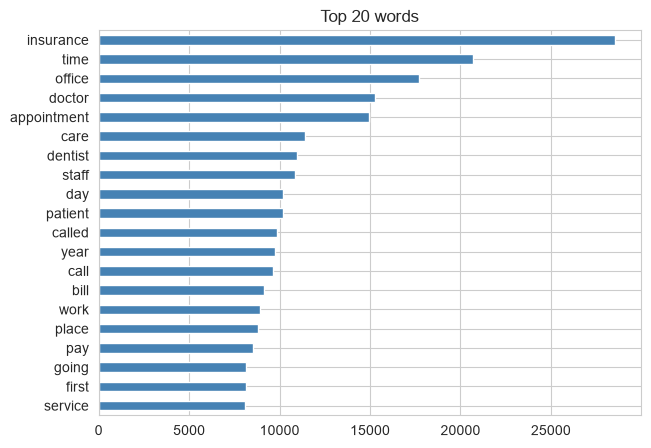

In [22]:
# Most frequent words in the cleaned text
def top_words_in(texts, n=20):
    cvx = CountVectorizer(max_features=n)
    counts = cvx.fit_transform(texts)
    return pd.Series(np.asarray(counts.sum(axis=0)).ravel(),
                     index=cvx.get_feature_names_out()).sort_values(ascending=False)

plt.figure(figsize=(7, 5))
top_words_in(df['text_clean']).sort_values().plot.barh(color='steelblue')
plt.title('Top 20 words'); plt.show()

**interpretation**

The top twenty words are displayed with the top three words being insurance, time and office. 

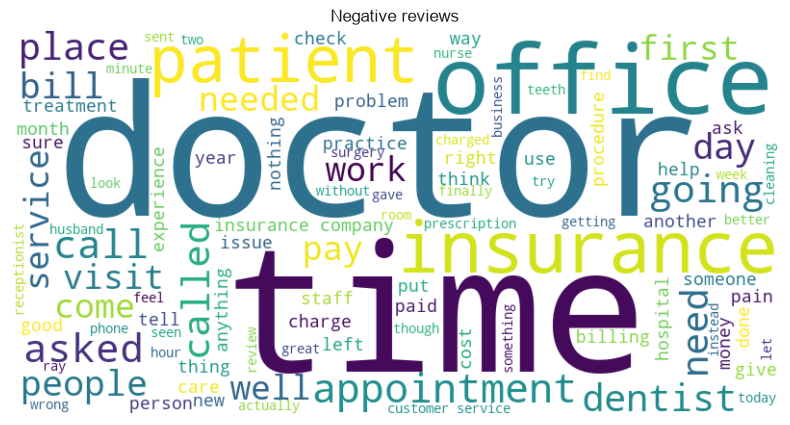

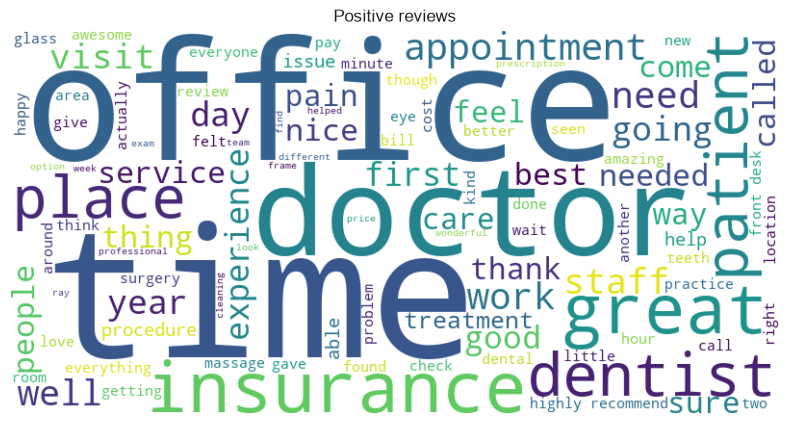

In [23]:
# Word clouds for negative versus positive reviews

def show_cloud(texts, title):
    wc = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(' '.join(texts))
    plt.figure(figsize=(10, 5)); plt.imshow(wc, interpolation='bilinear')
    plt.axis('off'); plt.title(title); plt.show()

for label in ['negative', 'positive']:
    subset = df.loc[df['star_sentiment'] == label, 'text_clean']
    show_cloud(subset.sample(min(5000, len(subset)), random_state=RANDOM_SEED), f'{label.title()} reviews')

**Interpretation:**

The word "insurance" ranks frst becaude the reviews were selected using the word
The negative clouds: Top words include office, time,  and doctor

The positive clouds: Top words include office, doctor, patient and insurance

The two clouds share the same top words "office" and "doctor"

Word clouds cannot separate sentiment, which is why the sentiment tools are needed.

| EDA finding | Modelling decision |
|---|---|
| 61% of reviews are negative, 35% positive and 4% neutral. | Judge sentiment with macro-F1 and negative recall, not accuracy alone; expect weak neutral results |
| Median review length 157 words | Enough text for LDA; the 10-word minimum removed only 3 reviews |
| 86 duplicate review texts | Removed before modelling so they do not count twice |
| Generic words (insurance, time, office) dominate | Kept in; they make topics less distinct (see limitations) |

# Feature Selection for LDA

LDA learns from word counts. The vocabulary is controlled with three settings:
- `min_df`: remove words that appear in very few reviews (typos, rare names)
- `max_df`: remove words that appear in a large share of reviews (they do not separate topics)
- `max_features`: keep only the most frequent remaining words

In [24]:
# Try three vocabulary settings and compare how much of each review is kept
settings = [(5, 0.7, 5000), (10, 0.5, 3000), (20, 0.3, 1500)]
rows = []
for min_df, max_df, max_feat in settings:
    c = CountVectorizer(min_df=min_df, max_df=max_df, max_features=max_feat)
    X = c.fit_transform(df['text_clean'])
    words_per_review = np.asarray(X.sum(axis=1)).ravel()
    rows.append({'min_df': min_df, 'max_df': max_df, 'max_features': max_feat,
                 'vocabulary size': X.shape[1],
                 'avg words kept per review': words_per_review.mean(),
                 'reviews left with no words': int((words_per_review == 0).sum())})
pd.DataFrame(rows).round(1)

,min_df,max_df,max_features,vocabulary size,avg words kept per review,reviews left with no words
0,5,0.7,5000,5000,77.4,0
1,10,0.5,3000,3000,72.7,0
2,20,0.3,1500,1500,62.3,0


**Interpretation**

the middle setting kept 72.7 words per review, about 94% of the widest setting’s 77.4, while removing rare and very common words

In [25]:
# Build the word-count matrix for LDA with the chosen setting
MIN_DF, MAX_DF, MAX_FEATURES = 10, 0.5, 3000
cv = CountVectorizer(min_df=MIN_DF, max_df=MAX_DF, max_features=MAX_FEATURES)
X_counts = cv.fit_transform(df['text_clean'])
vocab = cv.get_feature_names_out()
print('Document-term matrix:', X_counts.shape, '(reviews x words)')

Document-term matrix: (24596, 3000) (reviews x words)


# Topic Modelling with LDA (What are customers saying?)

In [26]:
# Helpers: top words of each topic and coherence score

# Create a binary document-term matrix
binary = (X_counts > 0).astype(np.int32)

# Keep the co-occurrence matrix sparse to reduce memory usage
co_occur = (binary.T @ binary).tocsr()

# Number of reviews containing each word
doc_freq = np.asarray(binary.sum(axis=0)).ravel()


def top_words(model, n=10):
    return [
        [str(vocab[i]) for i in comp.argsort()[:-n - 1:-1]]
        for comp in model.components_
    ]


def coherence_for(model, n=10):
    topic_scores = []

    for comp in model.components_:
        idx = comp.argsort()[:-n - 1:-1]
        pair_scores = []

        for m in range(1, len(idx)):
            for l in range(m):
                co_count = co_occur[idx[m], idx[l]]
                denominator = doc_freq[idx[l]]

                score = np.log((co_count + 1) / denominator)
                pair_scores.append(score)

        topic_scores.append(np.mean(pair_scores))

    return float(np.mean(topic_scores))


print("Coherence helper functions are ready.")

Coherence helper functions are ready.


{'topics': 3, 'coherence': -1.1537503669610736}
{'topics': 4, 'coherence': -1.2114829510057972}
{'topics': 5, 'coherence': -1.3252441356432565}
{'topics': 6, 'coherence': -1.3439110602673763}
{'topics': 7, 'coherence': -1.3440738906822889}
{'topics': 8, 'coherence': -1.4257441563477946}


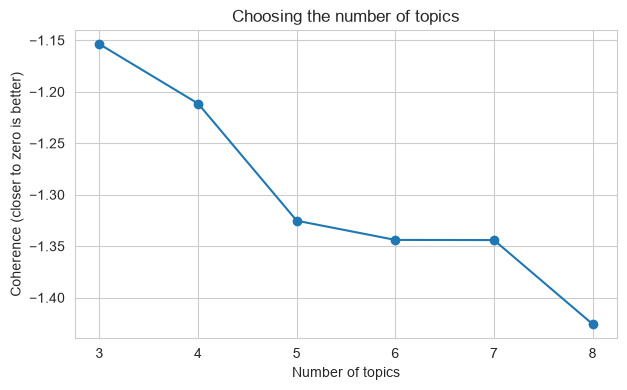

Best number of topics: 3


In [27]:
# Experiment 1: Compare different numbers of topics using coherence

k_results = []

for k in range(3, 9):
    m = LatentDirichletAllocation(
        n_components=k,
        learning_method='batch',
        max_iter=5,
        random_state=RANDOM_SEED
    )

    m.fit(X_counts)

    score = coherence_for(m)
    k_results.append({'topics': k, 'coherence': score})
    print({'topics': k, 'coherence': score})


k_df = pd.DataFrame(k_results)

plt.figure(figsize=(7, 4))
plt.plot(k_df['topics'], k_df['coherence'], marker='o')
plt.xlabel('Number of topics')
plt.ylabel('Coherence (closer to zero is better)')
plt.title('Choosing the number of topics')
plt.show()

BEST_K = int(k_df.loc[k_df['coherence'].idxmax(), 'topics'])

print('Best number of topics:', BEST_K)

In [28]:
# Experiment 2: different alpha values (doc_topic_prior).
# Small alpha = each review is about few topics; large alpha = reviews mix many topics
alpha_results = []
for alpha in [0.01, 0.1, 1.0]:
    m = LatentDirichletAllocation(n_components=BEST_K, doc_topic_prior=alpha, learning_method='batch',
                                  max_iter=10, random_state=RANDOM_SEED, n_jobs=-1)
    m.fit(X_counts)
    alpha_results.append({'alpha': alpha, 'coherence': coherence_for(m)})
    print(alpha_results[-1])
alpha_df = pd.DataFrame(alpha_results)
BEST_ALPHA = float(alpha_df.loc[alpha_df['coherence'].idxmax(), 'alpha'])
print('Best alpha:', BEST_ALPHA)

{'alpha': 0.01, 'coherence': -1.1852932392253634}
{'alpha': 0.1, 'coherence': -1.1693026034197944}
{'alpha': 1.0, 'coherence': -1.2048879693648884}
Best alpha: 0.1


**Interpretation**

Coherence was best at 3 topics (-1.154) and fell to -1.426 at 8. Alpha scores were -1.185 (0.01), -1.169 (0.1) and -1.205 (1.0), so 0.1 was best, though only slightly.

In [29]:
# Train the final LDA model and print the top words of each topic
lda = LatentDirichletAllocation(n_components=BEST_K, doc_topic_prior=BEST_ALPHA, learning_method='batch',
                                max_iter=20, random_state=RANDOM_SEED, n_jobs=-1)
doc_topic = lda.fit_transform(X_counts)
df['topic'] = doc_topic.argmax(axis=1)          # each review gets its strongest topic
df['topic_strength'] = doc_topic.max(axis=1)

for i, words in enumerate(top_words(lda, 10)):
    print(f'Topic {i}: {", ".join(words)}')

Topic 0: dentist, dental, office, cleaning, teeth, work, time, appointment, staff, tooth
Topic 1: doctor, time, office, call, appointment, called, bill, patient, pay, care
Topic 2: time, eye, glass, doctor, staff, place, great, exam, care, year


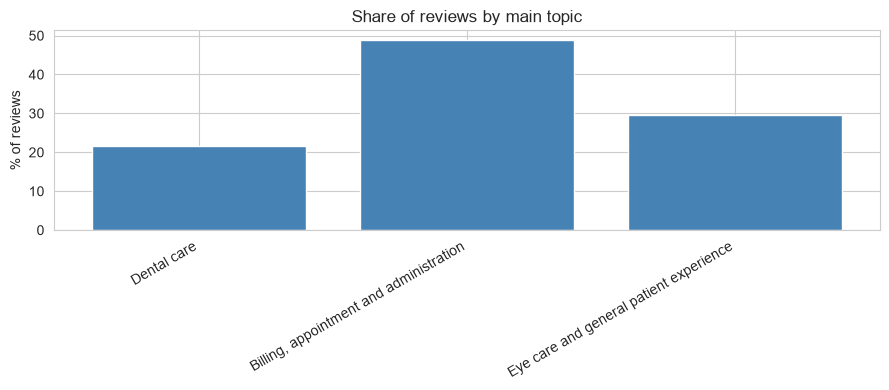

topic
0    21.61
1    48.87
2    29.52
Name: proportion, dtype: float64

--- Dental care ---
* So I have had a yelp account for a while now but never felt the need to review any businesses until today.  This review is actually way overdue and is for a root canal I had done while I was a student at UCSB in 2012.  The reason I am reviewing it today is because I finally went and had a root canal
* I really thought long and hard as to whether or not I should write a bad review.  I know it can really be damaging to one's reputation.  But I decided that in the end if I help one person to not go through what I did, then I believe that I did the right thing.    The previous review that says Dr. "C

--- Billing, appointment and administration ---
* I really dislike it when a business leaves me no choice but to leave a negative review.  First, because I have to write this distasteful review instead of the glowing reviews I prefer and second, because this company put me through such a distasteful

In [30]:
# Name each topic from its keywords. EDIT these labels after reading the words above
# (for example 'Billing and payments', 'Insurance and claims', 'Staff and communication')
TOPIC_LABELS = {
    0: 'Dental care',
    1: 'Billing, appointment and administration',
    2: 'Eye care and general patient experience'
}

topic_share = df['topic'].value_counts(normalize=True).sort_index() * 100
plt.figure(figsize=(9, 4))
plt.bar([TOPIC_LABELS[i] for i in topic_share.index], topic_share.values, color='steelblue')
plt.ylabel('% of reviews'); plt.title('Share of reviews by main topic')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

print(topic_share.round(2))

# The two most typical reviews of each topic, to check that the topic makes sense
for i in range(BEST_K):
    print(f'\n--- {TOPIC_LABELS[i]} ---')
    for text in df[df['topic'] == i].nlargest(2, 'topic_strength')['text']:
        print('*', text[:300].replace('\n', ' '))

**Interpretation** 

Topic 0’s top words (dentist, dental, teeth, cleaning) show dental care. Topic 1’s (call, appointment, bill, pay, office) show billing, appointment and administration. Topic 2’s (eye, glass, exam, doctor, staff) show eye care and general patient experience.

**Interpretation**

Billing, appointment and administration 48.87%, eye care and general patient experience 29.52%, and dental care 21.61%. Note that reviews were selected for insurance and billing words, which probably inflates the billing share, and that “time” appears in the top words of all three topics.

# Sentiment Analysis (How do customers feel?)

VADER and TextBlob are **lexicon-based**: they score words using a pre-built dictionary and fixed rules, so they do not learn from examples.
- **VADER** gives a *compound* score from -1 (very negative) to +1 (very positive).
- **TextBlob** gives a *polarity* score from -1 to +1.

A score becomes a label with two cut-offs: at or above the positive cut-off is positive, at or below the negative cut-off is negative, and anything between is neutral.

In [31]:
# Score every review with both tools, using the ORIGINAL text (capitals, punctuation and negations matter to them)
vader = SentimentIntensityAnalyzer()
df['vader'] = df['text'].apply(lambda t: vader.polarity_scores(t)['compound'])
df['blob'] = df['text'].apply(lambda t: TextBlob(t).sentiment.polarity)
df[['stars', 'vader', 'blob']].describe().round(3)

,stars,vader,blob
count,24596.000,24596.000,24596.000
mean,2.502,0.201,0.099
std,1.776,0.796,0.191
min,1.000,-0.999,-1.000
25%,1.000,-0.718,-0.008
50%,1.000,0.600,0.093
75%,5.000,0.953,0.213
max,5.000,1.000,1.000


In [32]:
# Helper functions: scores to labels, cut-off tuning, reporting
LABELS = ['negative', 'neutral', 'positive']

def to_label(scores, pos_thr, neg_thr):
    # At or above pos_thr = positive, at or below neg_thr = negative, otherwise neutral
    return np.where(scores >= pos_thr, 'positive', np.where(scores <= neg_thr, 'negative', 'neutral'))

def tune_thresholds(scores, y_true):
    # Try many cut-off pairs (wider range) and keep the best F1 for the NEGATIVE class,
    # which is the client's main concern
    best = (None, None, -1)
    for pos_thr in np.arange(0.05, 0.95, 0.05):
        for neg_thr in np.arange(-0.65, 0.35, 0.05):
            if neg_thr >= pos_thr:
                continue
            pred = to_label(scores, pos_thr, neg_thr)
            f1 = f1_score(y_true, pred, average='macro', labels=['negative'])
            if f1 > best[2]:
                best = (round(float(pos_thr), 2), round(float(neg_thr), 2), f1)
    return best


def evaluate(y_true, y_pred, name):
    # Print the report and return one row for the comparison table
    print(f'=== {name} ===')
    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Macro-F1': f1_score(y_true, y_pred, average='macro', labels=LABELS),
            'Negative recall': recall_score(y_true, y_pred, labels=['negative'], average='macro')}

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel('Predicted'); plt.ylabel('Actual (from stars)'); plt.title(title); plt.show()

## Model Evaluation ##

In [33]:
# Split the reviews. Cut-offs are tuned on the TRAIN part and judged on the unseen TEST part,
# so the improvement is not just fitted to the data we report on
train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=df['star_sentiment'],
                                       random_state=RANDOM_SEED)
y_train = df.loc[train_idx, 'star_sentiment'].values
y_test = df.loc[test_idx, 'star_sentiment'].values
results = []

## First model: default cut-offs

=== VADER (default cut-offs) ===
              precision    recall  f1-score   support

    negative       0.95      0.61      0.74      4495
     neutral       0.02      0.01      0.01       295
    positive       0.57      0.97      0.72      2589

    accuracy                           0.71      7379
   macro avg       0.51      0.53      0.49      7379
weighted avg       0.78      0.71      0.71      7379



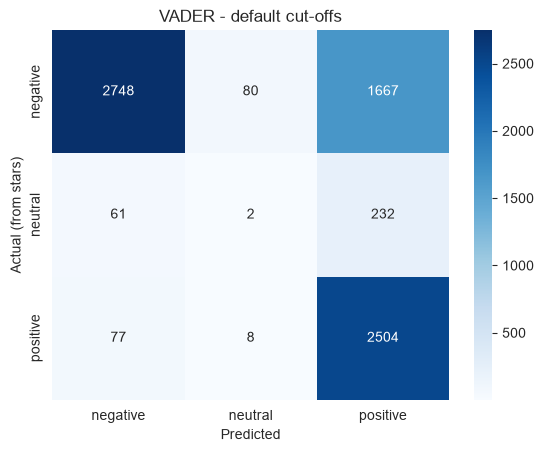

=== TextBlob (default cut-offs) ===
              precision    recall  f1-score   support

    negative       0.98      0.28      0.43      4495
     neutral       0.03      0.18      0.06       295
    positive       0.55      0.95      0.69      2589

    accuracy                           0.51      7379
   macro avg       0.52      0.47      0.39      7379
weighted avg       0.79      0.51      0.51      7379



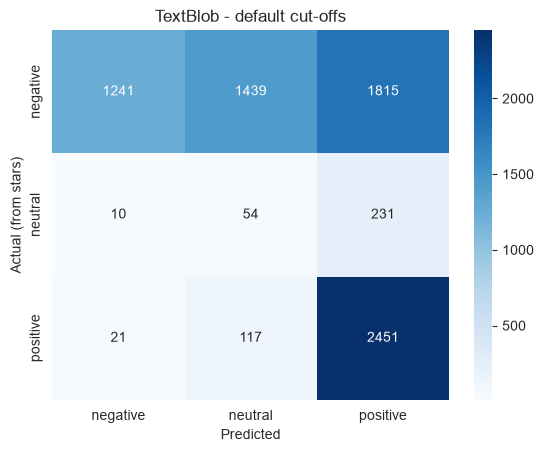

In [34]:
# Default cut-offs (+/-0.05, the usual convention), checked against the star-based labels on the test set
for tool, col in [('VADER', 'vader'), ('TextBlob', 'blob')]:
    pred = to_label(df.loc[test_idx, col].values, 0.05, -0.05)
    results.append(evaluate(y_test, pred, f'{tool} (default cut-offs)'))
    plot_cm(y_test, pred, f'{tool} - default cut-offs')

**Interpretation**

VADER negative precision 0.95 but recall 0.61; TextBlob negative recall only 0.28, so it misses 72% of negative reviews. Neutral F1 is about 0 for both (295 neutral test reviews).

## Improved model: tuned cut-offs

VADER: positive >= 0.35, negative <= 0.3 (train negative-class 0.784)
=== VADER (tuned cut-offs) ===
              precision    recall  f1-score   support

    negative       0.94      0.67      0.78      4495
     neutral       0.00      0.00      0.00       295
    positive       0.60      0.96      0.74      2589

    accuracy                           0.74      7379
   macro avg       0.51      0.54      0.51      7379
weighted avg       0.78      0.74      0.74      7379



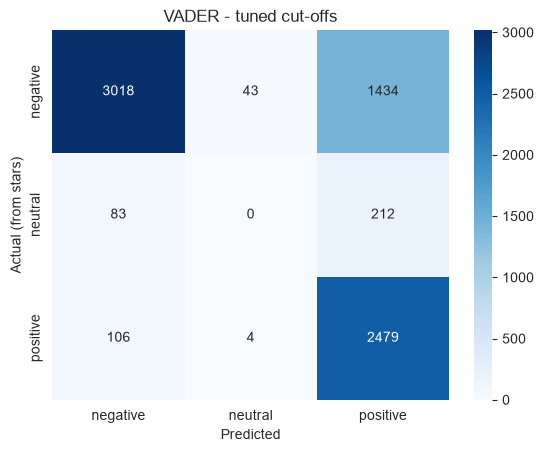

TextBlob: positive >= 0.2, negative <= 0.15 (train negative-class 0.851)
=== TextBlob (tuned cut-offs) ===
              precision    recall  f1-score   support

    negative       0.84      0.87      0.85      4495
     neutral       0.06      0.15      0.09       295
    positive       0.81      0.63      0.71      2589

    accuracy                           0.76      7379
   macro avg       0.57      0.55      0.55      7379
weighted avg       0.80      0.76      0.77      7379



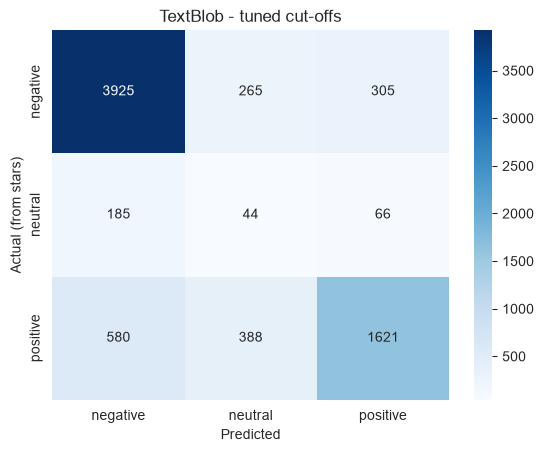

In [35]:
# Re-tune the cut-offs on the training data to fix the shortcoming seen above, then check on the same test set
tuned = {}
for tool, col in [('VADER', 'vader'), ('TextBlob', 'blob')]:
    pos_thr, neg_thr, train_f1 = tune_thresholds(df.loc[train_idx, col].values, y_train)
    tuned[tool] = (pos_thr, neg_thr)
    print(f'{tool}: positive >= {pos_thr}, negative <= {neg_thr} (train negative-class {train_f1:.3f})')
    pred = to_label(df.loc[test_idx, col].values, pos_thr, neg_thr)
    results.append(evaluate(y_test, pred, f'{tool} (tuned cut-offs)'))
    plot_cm(y_test, pred, f'{tool} - tuned cut-offs')

**Interpretation**

Tuning the cut-offs on the training data improved negative recall for both tools, from 0.28 to 0.87 for TextBlob and from 0.61 to 0.67 for VADER. TextBlob’s accuracy rose from 0.508 to 0.758, but its negative precision fell from 0.98 to 0.84, so more non-negative reviews were wrongly called negative. Neutral reviews almost disappeared after tuning for negative-class F1, so both tools now work mainly as positive/negative classifiers. VADER’s best negative cut-off (0.30) lay at the edge of the search range, so a wider range might improve it further

In [36]:
# Comparison table of all four versions
results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Macro-F1,Negative recall
0,VADER (default cut-offs),0.712,0.490,0.611
1,TextBlob (default cut-offs),0.508,0.393,0.276
2,VADER (tuned cut-offs),0.745,0.507,0.671
3,TextBlob (tuned cut-offs),0.758,0.550,0.873


**Interpretation**

Tuned TextBlob is best on all three metrics, which is why it is used from here.

# Bringing Both Objectives Together

,topic_label,reviews,mean_stars,mean_score,pct_negative
topic,,,,,
1,"Billing, appointment and administration",12021,1.40,0.01,85.37
0,Dental care,5315,3.22,0.17,46.83
2,Eye care and general patient experience,7260,3.81,0.19,38.57


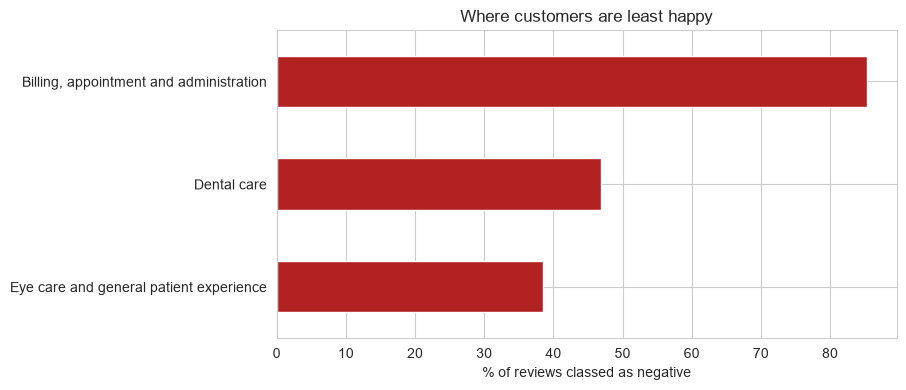

In [37]:
# For each LDA topic: how negative are the reviews? (best tool = TextBlob, tuned cut-offs)
BEST_TOOL, BEST_COL = 'TextBlob', 'blob'
best_pos, best_neg = tuned[BEST_TOOL]
df['sent_label'] = to_label(df[BEST_COL].values, best_pos, best_neg)

topic_sent = df.groupby('topic').agg(
    reviews=('text', 'count'),
    mean_stars=('stars', 'mean'),
    mean_score=(BEST_COL, 'mean'),
    pct_negative=('sent_label', lambda s: (s == 'negative').mean() * 100),
).round(2)
topic_sent.insert(0, 'topic_label', topic_sent.index.map(TOPIC_LABELS))
display(topic_sent.sort_values('pct_negative', ascending=False))

topic_sent.sort_values('pct_negative').plot.barh(x='topic_label', y='pct_negative', legend=False,
                                                 color='firebrick', figsize=(8, 4))
plt.xlabel('% of reviews classed as negative'); plt.ylabel(''); plt.title('Where customers are least happy'); plt.show()

**Interpretation**

Billing, appointment and administration: 12,021 reviews, lowest average rating (1.40 stars), 85.37% negative.

Dental care: 5,315 reviews, 3.22 stars, 46.83% negative.

Eye care and general patient experience: 7,260 reviews, 3.81 stars, 38.57% negative.

Billing and administration is the clear area of dissatisfaction. The negative percentages for the other two topics look high next to their star ratings because the tuned TextBlob labels some positive reviews as negative, so compare the topics against each other rather than reading the percentages as exact.

In [38]:
# Calculate the overall TextBlob sentiment distribution

overall_sentiment = (
    df['sent_label'].value_counts(normalize=True)
    .reindex(LABELS, fill_value=0) * 100
)

display(overall_sentiment.round(2))

sent_label
negative    63.23
neutral      9.45
positive    27.33
Name: proportion, dtype: float64

**Interpretation**

Using tuned TextBlob, 63.23% of reviews were classified as negative, 27.33% as positive and 9.45% as neutral. The negative share is close to the 61% of reviews rated 1–2 stars, so the tool’s overall picture matches the star ratings: most reviews in this dataset are negative.

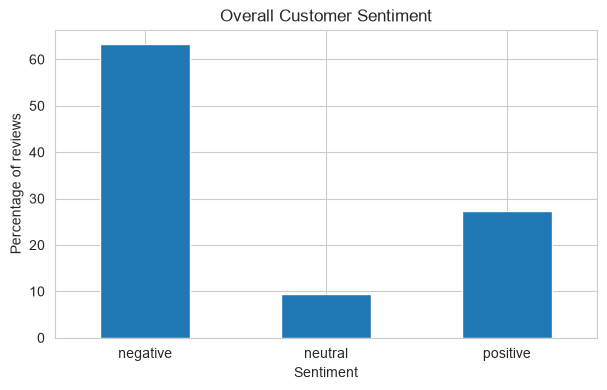

In [39]:
# Plot the overall sentiment distribution

overall_sentiment.plot(
    kind='bar',
    figsize=(7, 4),
    title='Overall Customer Sentiment',
    ylabel='Percentage of reviews',
    xlabel='Sentiment'
)

plt.xticks(rotation=0)
plt.show()

In [40]:
# Compare star-based sentiment with TextBlob sentiment

sentiment_comparison = pd.crosstab(
    df['star_sentiment'],
    df['sent_label'],
    normalize='index'
) * 100

display(sentiment_comparison.round(2))

sent_label,negative,neutral,positive
star_sentiment,,,
negative,86.81,6.03,7.16
neutral,62.70,16.67,20.63
positive,22.33,14.57,63.10


Tuned TextBlob classified 86.81% of 1–2 star reviews as negative but only 63.10% of 4–5 star reviews as positive, and 22.33% of positive-rated reviews were called negative. Neutral star ratings were mostly classed as negative (62.70%). This shows the trade-off of tuning for negative detection, and that star ratings are only an approximate reference.

In [41]:
# Manual check: 1-2 star reviews that the tuned VADER did not call negative
v_pos, v_neg = tuned['VADER']
test_df = df.loc[test_idx].copy()
test_df['pred'] = to_label(test_df['vader'].values, v_pos, v_neg)
missed = test_df[(test_df['star_sentiment'] == 'negative') & (test_df['pred'] != 'negative')]
print(len(missed), 'negative reviews were missed by the tuned VADER')
for _, r in missed.sample(min(5, len(missed)), random_state=RANDOM_SEED).iterrows():
    print(f"\nStars: {r['stars']} | VADER score: {r['vader']:.2f}\n{r['text'][:300]}")

1477 negative reviews were missed by the tuned VADER

Stars: 1.0 | VADER score: 0.94
If I spend $120 out of pocket, I expect a heck of a lot better than, "Ice it and take Tylenol." If I have 7 years of recurring back spasms, I want x-rays, not some lame prescription and the advice to get insurance. Thanks, I know I should have insurance, I can't afford it. That's why me dropping ove

Stars: 1.0 | VADER score: 0.92
I went for my "new patient" exam, during which I was told I would need a laser gum treatment, 10 fillings, 3 crowns, and 2 root canals.  This was preposterous because I had just had an exam 6 months prior and been given a clean bill of health. When I questioned the doctor about the extensive work he

Stars: 2.0 | VADER score: 0.35
My experience was very similar to those of the other two reviewers. Looooong wait times, about 8 minutes of physician time, medical assistants with a loose grasp (at best) of medical terminology, and a $96 'co-pay'. Granted, I haven't met my deducti

**Interpretation**

These are 1–2 star reviews that the tuned VADER did not call negative. The missed reviews mix polite or positive wording with a complaint, for example “pleased to see a nice, clean store… my experience was meh”, or complain about cost and insurance in a calm tone. This is one reason TextBlob was used for the topic analysis.

In [42]:
# Sentiment distribution within each topic

topic_sentiment = pd.crosstab(
    df['topic'].map(TOPIC_LABELS),
    df['sent_label'],
    normalize='index'
) * 100

display(topic_sentiment.round(2))

sent_label,negative,neutral,positive
topic,,,
"Billing, appointment and administration",85.37,6.10,8.54
Dental care,46.83,10.71,42.46
Eye care and general patient experience,38.57,14.08,47.36


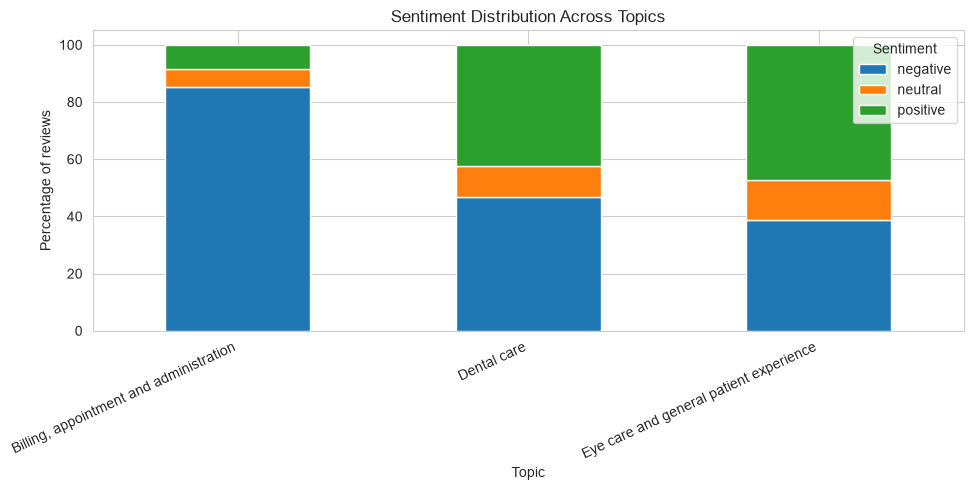

In [43]:
# Visualise sentiment across topics

topic_sentiment.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    title='Sentiment Distribution Across Topics',
    ylabel='Percentage of reviews',
    xlabel='Topic'
)

plt.xticks(rotation=25, ha='right')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

# Findings, Recommendations and Limitations


**Findings**

1. **Recurring themes:** Three main topics were identified: dental care, billing, appointment and administration, and eye care and general patient experience.

2. **Topic distribution:** Billing, appointment and administration accounted for the largest share of reviews (48.87%), followed by eye care and general patient experience (29.52%) and dental care (21.61%).

3. **Customer sentiment:** Using star ratings as the reference, tuned TextBlob performed best (accuracy 0.758, macro-F1 0.550, negative recall 0.873), ahead of tuned VADER (0.745, 0.507, 0.671).

4. Overall, 63.23% of reviews were classified as negative, 27.33% as positive and 9.45% as neutral.

5. Billing, appointment and administration is the most negative topic: 85.37% of its reviews were negative, with an average rating of 1.40 stars, compared with 46.83% for dental care and 38.57% for eye care.

**Recommendations**
Based on the findings, the following recommendations are proposed:

1. **Improve billing and administration:** The medical scheme should review billing processes, explain charges clearly and address recurring administrative complaints because 85.37% of the reviews in this topic were negative.
2. **Strengthen customer communication:** The medical scheme should improve communication with customers regarding billing queries, appointments and service-related concerns.
3. **Monitor customer feedback:** The medical scheme should regularly analyse customer reviews to identify recurring problems and monitor changes in customer sentiment; a person should check a sample of reviews the tool calls positive, because lexicon tools miss sarcasm and mixed reviews.

**Limitations**
- The reviews are from US healthcare providers on Yelp, not South African medical scheme members, so the findings show shared service concerns rather than one scheme's exact problems.
- Reviewers are self-selected and tend to be extreme.
- Star ratings are only a proxy for sentiment, and lexicon tools struggle with sarcasm and domain words.
- LDA topics depend on the number of topics and need human interpretation.
- Only reviews that mention insurance or billing words were kept, so some relevant reviews may be missed.
- Neutral reviews only accounted for 4% of the total reviews.
- Two of the three topics mainly show the provider type (dental care, eye care) rather than a type of concern.
- The sentiment cut-offs were tuned against star-based labels, so they carry any bias in the star ratings.

**Ethical and Legal Considerations**

The analysis uses publicly available customer reviews, but public availability does not remove the responsibility to protect individuals' privacy. Customer information should be handled responsibly, and identifiable details should not be unnecessarily reproduced or shared.

The Yelp dataset's terms and conditions must be respected, particularly regarding the redistribution of review data. The findings should also be interpreted carefully because the reviews are self-selected and may not represent the wider customer population.

If similar analysis were conducted for a South African medical scheme, the Protection of Personal Information Act (POPIA) would need to be considered when collecting, processing, storing and using personal information. Sentiment classifications should also not be used to make decisions about individual customers without appropriate human review.

**References**:

Blei, D. M., Ng, A. Y., & Jordan, M. I. 2003. Latent Dirichlet Allocation. Journal of Machine Learning Research, 3, 993–1022.

Hutto, C. J., & Gilbert, E. 2014. VADER: A Parsimonious Rule-Based Model for Sentiment Analysis of Social Media Text. Proceedings of the International AAAI Conference on Web and Social Media, 8(1), 216–225. 

Loria, S. (year). TextBlob.????

Mimno, D., Wallach, H., Talley, E., Leenders, M. and McCallum, A. 2011. Optimizing semantic coherence in topic models. Proceedings of the 2011 Conference on Empirical Methods in Natural Language Processing, pp. 262–272.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. and Duchesnay, E. 2011. Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, pp. 2825–2830.

Republic of South Africa. 2013. Protection of Personal Information Act 4 of 2013.

Yelp. 2023. Yelp Dataset Terms of Use. 

In [45]:
# Save the analysed reviews for your own use. Do NOT share them publicly: Yelp's terms restrict redistribution
df.drop(columns=['text_clean']).to_csv('reviews_analysed_PRIVATE.csv', index=False)
print('Saved. Keep this file and the yelp_dataset folder out of any public GitHub repository.')

Saved. Keep this file and the yelp_dataset folder out of any public GitHub repository.
